In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    'Order_ID': range(1001, 1021),
    'Product': ['Laptop', 'Mobile', 'Tablet', 'Headphones',
                'Laptop', 'Mobile', 'Tablet', 'Headphones',
                'Laptop', 'Mobile', 'Tablet', 'Headphones',
                'Laptop', 'Mobile', 'Tablet', 'Headphones',
                'Laptop', 'Mobile', 'Tablet', 'Headphones'],
    'Category': ['Electronics'] * 20,
    'Quantity': [2, 3, 1, 4, 2, 5, 2, 3, 1, 4,
                 3, 2, 1, 3, 4, 2, 2, 1, 3, 5],
    'Price': [50000, 20000, 15000, 2000, 50000,
              20000, 15000, 2000, 50000, 20000,
              15000, 2000, 50000, 20000, 15000,
              2000, 50000, 20000, 15000, 2000],
    'Region': ['North', 'South', 'East', 'West',
               'North', 'South', 'East', 'West',
               'North', 'South', 'East', 'West',
               'North', 'South', 'East', 'West',
               'North', 'South', 'East', 'West'],
    'Payment': ['UPI', 'Card', 'Cash', 'UPI',
                'Card', 'UPI', 'Cash', 'Card',
                'UPI', 'Cash', 'Card', 'UPI',
                'Cash', 'Card', 'UPI', 'Cash',
                'Card', 'UPI', 'Cash', 'Card']
}

df = pd.DataFrame(data)

df.to_csv("ecommerce_sales.csv", index=False)

df.head()

,Order_ID,Product,Category,Quantity,Price,Region,Payment
0,1001,Laptop,Electronics,2,50000,North,UPI
1,1002,Mobile,Electronics,3,20000,South,Card
2,1003,Tablet,Electronics,1,15000,East,Cash
3,1004,Headphones,Electronics,4,2000,West,UPI
4,1005,Laptop,Electronics,2,50000,North,Card


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nFirst 10 Records:")
display(df.head(10))

Dataset Shape: (20, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Order_ID  20 non-null     int64
 1   Product   20 non-null     str  
 2   Category  20 non-null     str  
 3   Quantity  20 non-null     int64
 4   Price     20 non-null     int64
 5   Region    20 non-null     str  
 6   Payment   20 non-null     str  
dtypes: int64(3), str(4)
memory usage: 1.7 KB

Statistical Summary:


,Order_ID,Quantity,Price
count,20.00000,20.000000,20.000000
mean,1010.50000,2.650000,21750.000000
std,5.91608,1.268028,18040.524558
min,1001.00000,1.000000,2000.000000
25%,1005.75000,2.000000,11750.000000
50%,1010.50000,2.500000,17500.000000
75%,1015.25000,3.250000,27500.000000
max,1020.00000,5.000000,50000.000000



First 10 Records:


,Order_ID,Product,Category,Quantity,Price,Region,Payment
0,1001,Laptop,Electronics,2,50000,North,UPI
1,1002,Mobile,Electronics,3,20000,South,Card
2,1003,Tablet,Electronics,1,15000,East,Cash
3,1004,Headphones,Electronics,4,2000,West,UPI
4,1005,Laptop,Electronics,2,50000,North,Card
5,1006,Mobile,Electronics,5,20000,South,UPI
6,1007,Tablet,Electronics,2,15000,East,Cash
7,1008,Headphones,Electronics,3,2000,West,Card
8,1009,Laptop,Electronics,1,50000,North,UPI
9,1010,Mobile,Electronics,4,20000,South,Cash


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.dropna()

df['Revenue'] = df['Quantity'] * df['Price']

print("\nData Cleaning Completed!")
display(df.head())

Missing Values:
Order_ID    0
Product     0
Category    0
Quantity    0
Price       0
Region      0
Payment     0
dtype: int64

Duplicate Records: 0

Data Cleaning Completed!


,Order_ID,Product,Category,Quantity,Price,Region,Payment,Revenue
0,1001,Laptop,Electronics,2,50000,North,UPI,100000
1,1002,Mobile,Electronics,3,20000,South,Card,60000
2,1003,Tablet,Electronics,1,15000,East,Cash,15000
3,1004,Headphones,Electronics,4,2000,West,UPI,8000
4,1005,Laptop,Electronics,2,50000,North,Card,100000


In [5]:
print("Total Revenue:", df['Revenue'].sum())

print("Total Orders:", df['Order_ID'].nunique())

print("Total Quantity Sold:", df['Quantity'].sum())

print("Average Order Value:",
      df['Revenue'].sum() / df['Order_ID'].nunique())

print("\nProduct-wise Revenue:")
display(df.groupby('Product')['Revenue'].sum().sort_values(ascending=False))

print("\nRegion-wise Revenue:")
display(df.groupby('Region')['Revenue'].sum())

Total Revenue: 947000
Total Orders: 20
Total Quantity Sold: 53
Average Order Value: 47350.0

Product-wise Revenue:


Product
Laptop        400000
Mobile        320000
Tablet        195000
Headphones     32000
Name: Revenue, dtype: int64


Region-wise Revenue:


Region
East     195000
North    400000
South    320000
West      32000
Name: Revenue, dtype: int64

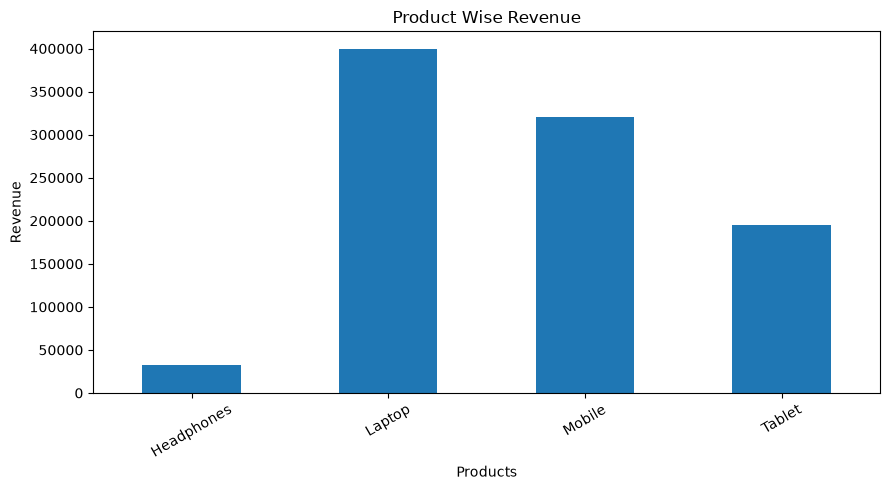

In [6]:
plt.figure(figsize=(9,5))

df.groupby('Product')['Revenue'].sum().plot(
    kind='bar', title='Product Wise Revenue'
)

plt.xlabel("Products")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

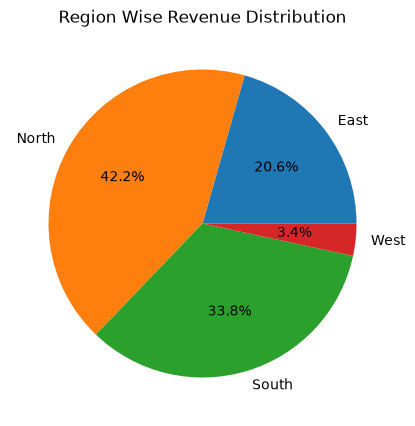

In [7]:
plt.figure(figsize=(8,5))

df.groupby('Region')['Revenue'].sum().plot(
    kind='pie', autopct='%1.1f%%'
)

plt.title("Region Wise Revenue Distribution")
plt.ylabel("")
plt.show()

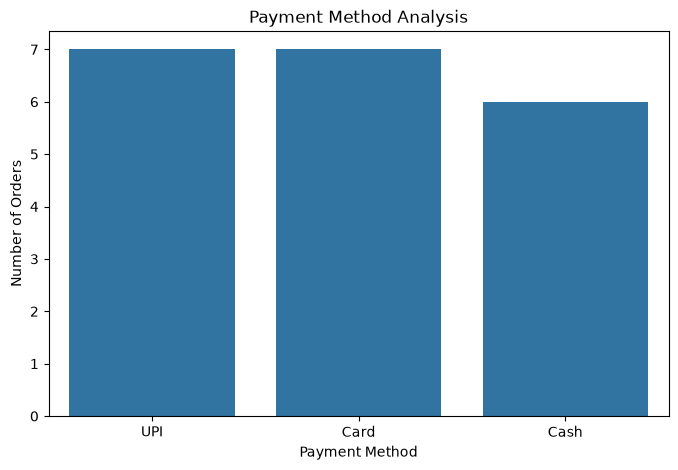

In [8]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Payment')

plt.title("Payment Method Analysis")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.show()

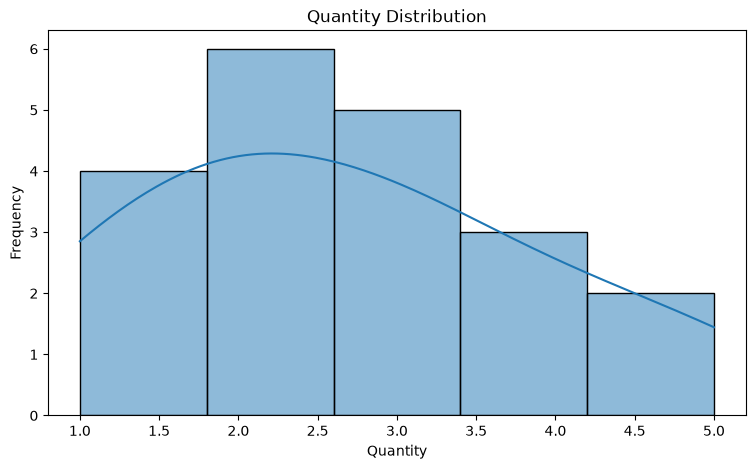

In [9]:
plt.figure(figsize=(9,5))

sns.histplot(df['Quantity'], bins=5, kde=True)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

In [10]:
best_product = df.groupby('Product')['Revenue'].sum().idxmax()

best_region = df.groupby('Region')['Revenue'].sum().idxmax()

best_payment = df['Payment'].value_counts().idxmax()

print("BUSINESS INSIGHTS")
print("--------------------------")

print("Best Selling Product:", best_product)
print("Highest Revenue Region:", best_region)
print("Most Used Payment Method:", best_payment)

print("Total Revenue:", df['Revenue'].sum())
print("Total Orders:", df['Order_ID'].nunique())

BUSINESS INSIGHTS
--------------------------
Best Selling Product: Laptop
Highest Revenue Region: North
Most Used Payment Method: UPI
Total Revenue: 947000
Total Orders: 20


In [11]:
df.to_csv("Final_Cleaned_Ecommerce_Sales.csv", index=False)

print("Final cleaned dataset exported successfully!")

Final cleaned dataset exported successfully!


# E-Commerce Sales Data Analysis

## Project Overview
This project focuses on analyzing e-commerce sales data using Python. The objective is to understand sales performance, product demand, regional revenue distribution and customer payment preferences.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Objectives
1. Analyze e-commerce sales data.
2. Clean and prepare the dataset.
3. Identify top-performing products.
4. Compare regional sales performance.
5. Visualize important business metrics.
6. Generate actionable business insights.

## Conclusion
The project demonstrates the complete data analytics workflow, including data preparation, exploratory analysis, visualization and business insight generation. The findings can help businesses understand their sales performance and make data-driven decisions.

**Project By:** Ronak Kaushik  
**Internship:** SWYNEX